# 02 · Data Cleaning
Goal: remove outliers, fill every missing value with a *reason*, fix types. Output → `data/processed/`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
train = pd.read_csv('../data/train.csv'); test = pd.read_csv('../data/test.csv')
print(train.shape, test.shape)

(1460, 81) (1459, 80)


## 2.1 Outliers
The two houses with `GrLivArea > 4000` but a low price are partial sales (the dataset author's own advice). They distort every linear model.

In [2]:
mask = (train.GrLivArea > 4000) & (train.SalePrice < 300000)
print('Removing', mask.sum(), 'rows')
train = train[~mask].reset_index(drop=True)

Removing 2 rows


## 2.2 Combine train + test
So both get identical treatment. Target is log-transformed (skew 1.88 → ~0.12, see EDA).

In [3]:
y = np.log1p(train.pop('SalePrice'))
n_train = len(train)
test_ids = test['Id']
df = pd.concat([train, test], ignore_index=True).drop(columns=['Id'])
miss = df.isna().sum(); miss = miss[miss>0].sort_values(ascending=False)
print(len(miss), 'columns with missing values'); miss.head(10)

34 columns with missing values


PoolQC         2908
MiscFeature    2812
Alley          2719
Fence          2346
MasVnrType     1766
FireplaceQu    1420
LotFrontage     486
GarageQual      159
GarageYrBlt     159
GarageCond      159
dtype: int64

## 2.3 Imputation strategy
- **NA means 'feature absent'** (no pool, no garage, no basement…) → `'None'` / `0`
- **Truly missing, few rows** → mode
- **LotFrontage** → median of the same neighborhood (lots in a neighborhood are similar)
- `Utilities` is 99.9% one value → drop

In [4]:
NONE_CAT = ['PoolQC','MiscFeature','Alley','Fence','FireplaceQu','GarageType','GarageFinish',
            'GarageQual','GarageCond','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1',
            'BsmtFinType2','MasVnrType']
ZERO_NUM = ['GarageYrBlt','GarageArea','GarageCars','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF',
            'TotalBsmtSF','BsmtFullBath','BsmtHalfBath','MasVnrArea']
MODE_CAT = ['MSZoning','Electrical','KitchenQual','Exterior1st','Exterior2nd','SaleType']

print(df.Utilities.value_counts())
df = df.drop(columns='Utilities')
for c in NONE_CAT: df[c] = df[c].fillna('None')
for c in ZERO_NUM: df[c] = df[c].fillna(0)
for c in MODE_CAT: df[c] = df[c].fillna(df[c].mode()[0])
df['Functional'] = df['Functional'].fillna('Typ')   # data description: assume typical
df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median()))
df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())

Utilities
AllPub    2914
NoSeWa       1
Name: count, dtype: int64


## 2.4 Data errors & types
One test house has `GarageYrBlt = 2207` (typo). Numeric codes that are really categories (`MSSubClass`, month/year sold) become strings.

In [5]:
bad = df.GarageYrBlt > 2010
print('GarageYrBlt typos:', bad.sum())
df.loc[bad,'GarageYrBlt'] = df.loc[bad,'YearBuilt']
for c in ['MSSubClass','MoSold','YrSold']: df[c] = df[c].astype(str)
assert df.isna().sum().sum() == 0
print('Remaining NaNs:', df.isna().sum().sum())

GarageYrBlt typos: 1
Remaining NaNs: 0


## 2.5 Sanity check & save

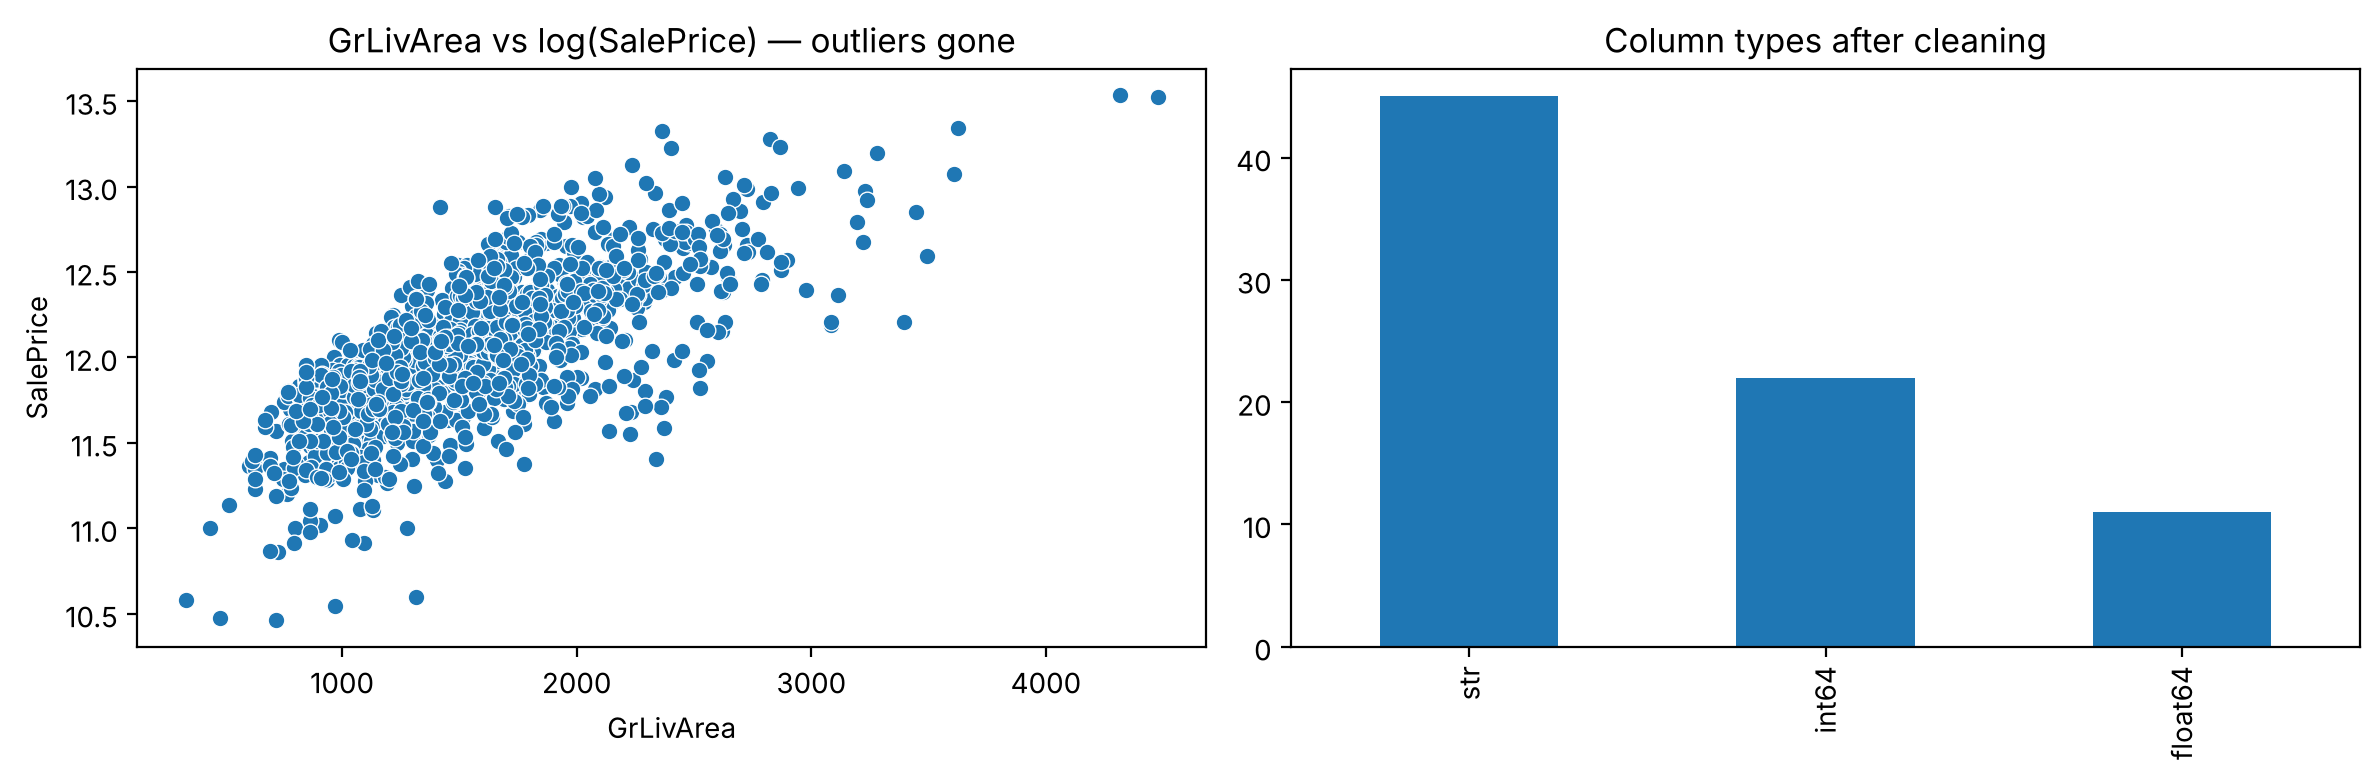

saved (2917, 78)


In [6]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.scatterplot(x=train.GrLivArea, y=y, ax=ax[0]); ax[0].set_title('GrLivArea vs log(SalePrice) — outliers gone')
df.dtypes.value_counts().plot.bar(ax=ax[1], title='Column types after cleaning'); plt.tight_layout(); plt.show()

df.iloc[:n_train].assign(LogSalePrice=y.values).to_csv('../data/processed/clean_train.csv', index=False)
df.iloc[n_train:].assign(Id=test_ids.values).to_csv('../data/processed/clean_test.csv', index=False)
print('saved', df.shape)